# Batch-size-1 replay timing

**Complete** · queue · ETA 0h 00m 00s 

One image and one update per arrival at LR 0.000075. Periodic and random each allocate exactly one quarter of every 128-arrival block to replay, using the same causal 256–2,048-frame age sampler. The always-current checkpoint and trace come from the completed singleton run.

| Seed | Arm | State | Progress | Paired cases |
| --- | --- | --- | --- | --- |
 | 2026 | Always current (saved) | complete | 1/1 |  | 
 | 2026 | Paired calibration | complete | 8,000/8,000 | 12 | 
 | 2026 | Periodic 25% | complete | 72,000/72,000 | 96 | 
 | 2026 | Exact-budget random 25% | complete | 72,000/72,000 | 0 | 
 | 2027 | Always current (saved) | complete | 1/1 |  | 
 | 2027 | Paired calibration | complete | 8,000/8,000 | 12 | 
 | 2027 | Periodic 25% | complete | 72,000/72,000 | 96 | 
 | 2027 | Exact-budget random 25% | complete | 72,000/72,000 | 0 | 
 | 2028 | Always current (saved) | complete | 1/1 |  | 
 | 2028 | Paired calibration | complete | 8,000/8,000 | 12 | 
 | 2028 | Periodic 25% | complete | 72,000/72,000 | 96 | 
 | 2028 | Exact-budget random 25% | complete | 72,000/72,000 | 0 | 



## Reconstruction loss and RankMe during training

Each point averages up to 1,000 checkpointed pre-action measurements. Loss is masked-patch MSE. RankMe is measured on unmasked encoder embeddings from the rolling bank. The vertical line at 8,000 images marks the shared calibration checkpoint for each seed.

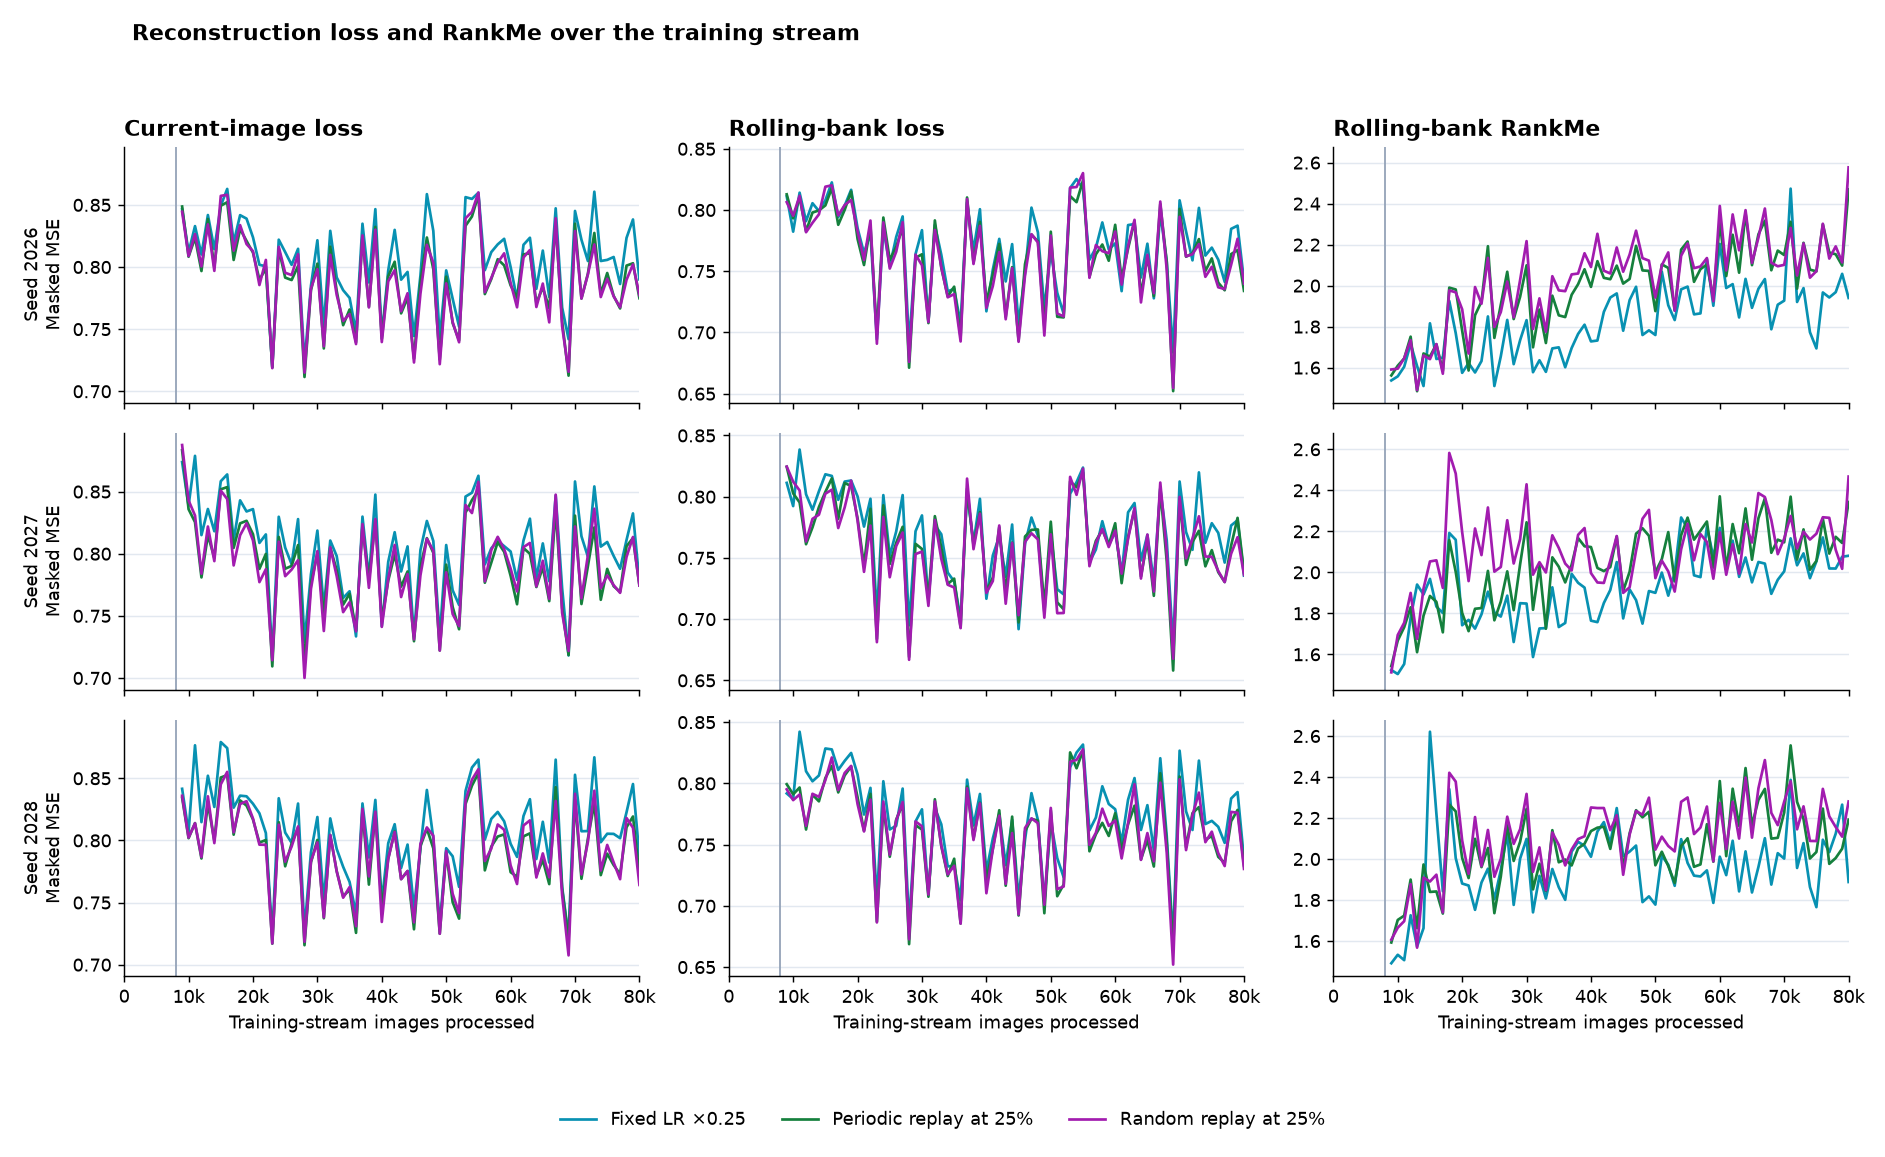

Run the watcher cell at the bottom for live plots while this notebook is open.

## Validation and held-out outcomes

| Seed | Arm | New panel MSE | New panel RankMe | Historical MSE | Replay steps | Training time |
| --- | --- | --- | --- | --- | --- | --- |
 | 2026 | Always current (saved) | 0.903932 | 3.3260 | 0.864500 | 0 | 0h 21m 05s | 
 | 2026 | Periodic 25% | 0.853643 | 4.4390 | 0.838726 | 18,000 | 0h 12m 32s | 
 | 2026 | Exact-budget random 25% | 0.850321 | 4.5174 | 0.841022 | 18,000 | 0h 12m 29s | 
 | 2027 | Always current (saved) | 0.921959 | 3.8333 | 0.895730 | 0 | 0h 20m 46s | 
 | 2027 | Periodic 25% | 0.856134 | 4.2681 | 0.833647 | 18,000 | 0h 12m 28s | 
 | 2027 | Exact-budget random 25% | 0.856766 | 4.1839 | 0.841845 | 18,000 | 0h 12m 35s | 
 | 2028 | Always current (saved) | 0.898699 | 3.8728 | 0.873301 | 0 | 0h 20m 57s | 
 | 2028 | Periodic 25% | 0.848041 | 4.1798 | 0.837876 | 18,000 | 0h 13m 06s | 
 | 2028 | Exact-budget random 25% | 0.851182 | 4.2684 | 0.838419 | 18,000 | 0h 12m 31s | 

Periodic 25% minus always current MSE **-0.055591**, 95% clip interval [-0.072221, -0.040489], 3 paired seeds.

Exact-budget random 25% minus always current MSE **-0.055441**, 95% clip interval [-0.072023, -0.040465], 3 paired seeds.

Random minus periodic MSE **+0.000150**, 95% clip interval [-0.002439, +0.002876], 3 paired seeds.

## Paired action audit

The audit branches Current and Replay from the same periodic-trajectory state. Both branches then follow the same fixed schedule on 64 recorded future frames. Each four-state group assigns exactly one replay to the immediate rule, the delayed oracle, and periodic. These choices diagnose headroom on the sampled states.

| Split | States | Ranking agreement | Immediate-rule gain | Oracle gain | Lower 90% | Historical excess MSE | Gain gate |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | development | 144 | 38.2% | -0.000007 | +0.000214 | +0.000153 | +0.000070 | fail | 
 | confirmation | 144 | 51.4% | +0.000023 | +0.000330 | +0.000237 | +0.000038 | fail | 

In [ ]:
# Run this cell to watch the training curves. Interrupt it to stop watching.
from IPython.display import Image, clear_output, display
from pathlib import Path
import json, time

chart_path = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\batch1-replay-timing\\training-curves.png')
status_path = chart_path.with_name('status.json')
while True:
    try:
        status = json.loads(status_path.read_text(encoding='utf-8'))
        png = chart_path.read_bytes()
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    display(Image(data=png))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)
